# LoRA Fine-Tuning for Intent Detection and Slot Filling


In [1]:
!pip -q install transformers accelerate

In [2]:
import json, os, random, re, collections
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

## 1. Download the dataset

Original source: <https://github.com/sonos/nlu-benchmark/tree/master/2017-06-custom-intent-engines> (CC0-1.0 license).



In [3]:
if not os.path.exists("nlu-benchmark"):
    !git clone --depth 1 https://github.com/sonos/nlu-benchmark.git

DATA_DIR = "nlu-benchmark/2017-06-custom-intent-engines"
INTENTS = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print(INTENTS)

['AddToPlaylist', 'BookRestaurant', 'GetWeather', 'PlayMusic', 'RateBook', 'SearchCreativeWork', 'SearchScreeningEvent']


## 2. Load and convert

Each raw example is a list of text chunks; chunks that are slots carry an `entity` name:

```json
{"data": [{"text": "What will the weather be "},
          {"text": "this year", "entity": "timeRange"},
          {"text": " in "}, ...]}
```

We join the chunks to get the sentence and collect the `entity` chunks as slots.

Two details found while checking the files:
- One file (`train_PlayMusic_full.json`) stores emoji as UTF-16 surrogate pairs, which breaks normal UTF-8 decoding, so `load_json` repairs them.
- In a few sentences the same slot appears twice (e.g. two artists). Then the slot value becomes a list instead of a string.

In [4]:
def load_json(path):
    raw = open(path, "rb").read()
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError:
        # emoji written as surrogate pairs -> decode them, then rebuild real characters
        text = raw.decode("utf-8", "surrogatepass").encode("utf-16", "surrogatepass").decode("utf-16")
    return json.loads(text)


def convert(raw_example, intent):
    sentence = "".join(chunk["text"] for chunk in raw_example["data"])
    slots = {}
    for chunk in raw_example["data"]:
        if "entity" not in chunk:
            continue
        name, value = chunk["entity"], chunk["text"].strip()
        if name in slots:                                    # repeated slot -> list
            slots[name] = slots[name] if isinstance(slots[name], list) else [slots[name]]
            slots[name].append(value)
        else:
            slots[name] = value
    return {"text": sentence.strip(), "intent": intent, "slots": slots}


def load_split(kind):
    examples = []
    for intent in INTENTS:
        fname = f"train_{intent}_full.json" if kind == "train" else f"validate_{intent}.json"
        for raw in load_json(os.path.join(DATA_DIR, intent, fname))[intent]:
            examples.append(convert(raw, intent))
    return examples


train = load_split("train")
test = load_split("validate")      # the official 700-sentence held-out set is used as our test set

# remove the few sentences that appear in both splits
test_texts = {e["text"] for e in test}
before = len(train)
train = [e for e in train if e["text"] not in test_texts]
print(f"train: {len(train)}  (removed {before - len(train)} overlapping)   test: {len(test)}")
print(json.dumps(train[0], ensure_ascii=False, indent=1))

train: 13780  (removed 4 overlapping)   test: 700
{
 "text": "Add another song to the Cita Romántica playlist.",
 "intent": "AddToPlaylist",
 "slots": {
  "music_item": "song",
  "playlist": "Cita Romántica"
 }
}


## 3. Explore the data

In [5]:
df = pd.DataFrame(
    [{"split": "train", **e} for e in train] + [{"split": "test", **e} for e in test]
)
df["n_words"] = df["text"].str.split().str.len()
df["n_slots"] = df["slots"].apply(lambda s: sum(len(v) if isinstance(v, list) else 1 for v in s.values()))

print("Examples per intent:")
print(df.groupby(["intent", "split"]).size().unstack())
print()
print(f"Average sentence length: {df['n_words'].mean():.1f} words (max {df['n_words'].max()})")
print(f"Average slots per sentence: {df['n_slots'].mean():.2f}")
print(f"Sentences with no slot: {(df['n_slots'] == 0).sum()}")

Examples per intent:
split                 test  train
intent                           
AddToPlaylist          100   1942
BookRestaurant         100   1973
GetWeather             100   1999
PlayMusic              100   1999
RateBook               100   1955
SearchCreativeWork     100   1954
SearchScreeningEvent   100   1958

Average sentence length: 8.9 words (max 35)
Average slots per sentence: 2.59
Sentences with no slot: 0


39 slot types in the training set


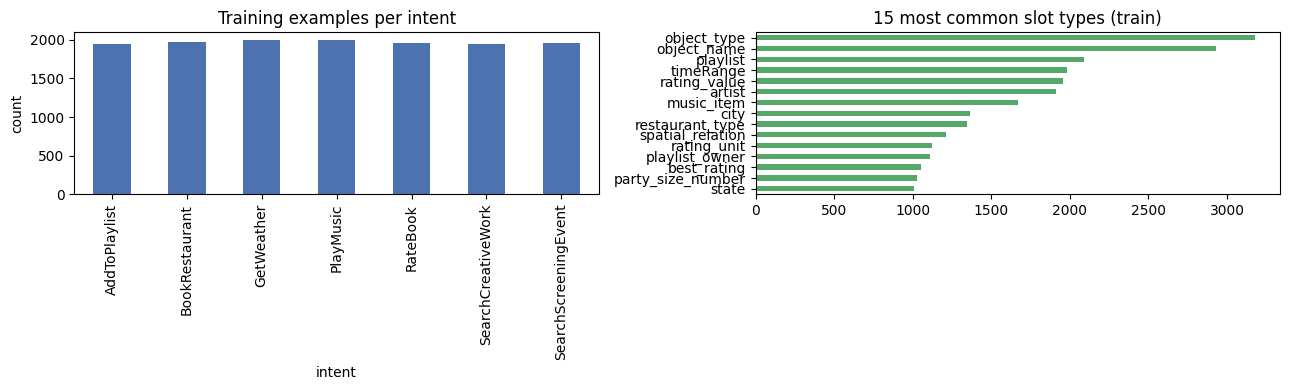

In [6]:
slot_counts = collections.Counter(name for e in train for name in e["slots"])
print(f"{len(slot_counts)} slot types in the training set")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df[df.split == "train"]["intent"].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Training examples per intent"); axes[0].set_ylabel("count")
pd.Series(dict(slot_counts.most_common(15))).plot.barh(ax=axes[1], color="#55A868")
axes[1].invert_yaxis(); axes[1].set_title("15 most common slot types (train)")
plt.tight_layout(); plt.show()

In [7]:
# a few random examples in the final input -> output format
for e in random.sample(train, 3):
    print("IN :", e["text"])
    print("OUT:", json.dumps({"intent": e["intent"], "slots": e["slots"]}, ensure_ascii=False))
    print()

IN : find a photograph called The Wish List
OUT: {"intent": "SearchCreativeWork", "slots": {"object_type": "photograph", "object_name": "The Wish List"}}

IN : add the name covenant to the playlist Fusion Fest
OUT: {"intent": "AddToPlaylist", "slots": {"entity_name": "covenant", "playlist": "Fusion Fest"}}

IN : Add best of uetoaya to Wild Country
OUT: {"intent": "AddToPlaylist", "slots": {"entity_name": "best of uetoaya", "playlist": "Wild Country"}}



### Save the processed splits

Each line is `{"text", "intent", "slots"}`. These files are what the LoRA training stage will read.

In [8]:
os.makedirs("data", exist_ok=True)
for name, split in [("train", train), ("test", test)]:
    with open(f"data/{name}.jsonl", "w", encoding="utf-8") as f:
        for e in split:
            f.write(json.dumps(e, ensure_ascii=False) + "\n")
print(os.listdir("data"))

['baseline_scores.json', 'test.jsonl', 'train.jsonl']


## 4. Evaluation metrics

For each test sentence the model's text output is parsed as JSON and compared with the gold label:

| Metric | Meaning |
|---|---|
| **JSON valid rate** | share of outputs that parse into `{"intent": ..., "slots": {...}}` |
| **Intent accuracy** | share of sentences with the correct intent |
| **Slot precision / recall / F1** | each slot is a `(slot name, value)` pair; a pair counts as correct only if both match exactly (case-insensitive) |

An output that is not valid JSON counts as a wrong intent and zero predicted slots.

In [9]:
def parse_output(text):
    """Pull the first {...} block out of the model output and parse it. Returns None if impossible."""
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if not match:
        return None
    try:
        obj = json.loads(match.group(0))
    except json.JSONDecodeError:
        return None
    if not isinstance(obj, dict) or not isinstance(obj.get("slots", {}), dict):
        return None
    return obj


def slot_pairs(slots):
    pairs = set()
    for name, value in (slots or {}).items():
        for v in (value if isinstance(value, list) else [value]):
            pairs.add((str(name).lower().strip(), str(v).lower().strip()))
    return pairs


def evaluate(gold_examples, outputs):
    n_valid = n_intent = tp = n_pred = n_gold = 0
    for gold, out in zip(gold_examples, outputs):
        pred = parse_output(out)
        gold_pairs = slot_pairs(gold["slots"])
        n_gold += len(gold_pairs)
        if pred is None:
            continue
        n_valid += 1
        n_intent += str(pred.get("intent", "")).strip() == gold["intent"]
        pred_pairs = slot_pairs(pred.get("slots", {}))
        n_pred += len(pred_pairs)
        tp += len(pred_pairs & gold_pairs)
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_gold if n_gold else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    n = len(gold_examples)
    return {"json_valid": n_valid / n, "intent_acc": n_intent / n,
            "slot_precision": p, "slot_recall": r, "slot_f1": f1}


# sanity check: the gold labels themselves must score 100%
gold_as_text = [json.dumps({"intent": e["intent"], "slots": e["slots"]}) for e in test]
print(evaluate(test, gold_as_text))

{'json_valid': 1.0, 'intent_acc': 1.0, 'slot_precision': 1.0, 'slot_recall': 1.0, 'slot_f1': 1.0}


## 5. Zero-shot baseline (before fine-tuning)

The base model gets the list of intents and slot names in the prompt and is asked to answer in JSON. This is the number LoRA has to beat.

To keep it quick, the baseline runs on a random sample of 140 test sentences (20 per intent). Set `N_PER_INTENT = None` to use all 700.

In [10]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"          # needed for batched generation with a decoder-only model
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device)
model.eval()
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M")

device: cuda


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

parameters: 494M


In [11]:
SLOT_NAMES = sorted(slot_counts)

SYSTEM_PROMPT = (
    "You are a natural language understanding system for a voice assistant. "
    "Given a user command, return ONLY a JSON object of the form "
    '{"intent": <intent>, "slots": {<slot name>: <exact text from the command>}}.\n'
    f"Possible intents: {', '.join(INTENTS)}.\n"
    f"Possible slot names: {', '.join(SLOT_NAMES)}.\n"
    "Copy slot values exactly as they appear in the command. Use an empty object if there are no slots."
)

def build_prompt(sentence):
    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": sentence}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

print(build_prompt(test[0]["text"]))

<|im_start|>system
You are a natural language understanding system for a voice assistant. Given a user command, return ONLY a JSON object of the form {"intent": <intent>, "slots": {<slot name>: <exact text from the command>}}.
Possible intents: AddToPlaylist, BookRestaurant, GetWeather, PlayMusic, RateBook, SearchCreativeWork, SearchScreeningEvent.
Possible slot names: album, artist, best_rating, city, condition_description, condition_temperature, country, cuisine, current_location, entity_name, facility, genre, geographic_poi, location_name, movie_name, movie_type, music_item, object_location_type, object_name, object_part_of_series_type, object_select, object_type, party_size_description, party_size_number, playlist, playlist_owner, poi, rating_unit, rating_value, restaurant_name, restaurant_type, served_dish, service, sort, spatial_relation, state, timeRange, track, year.
Copy slot values exactly as they appear in the command. Use an empty object if there are no slots.<|im_end|>
<|i

In [12]:
@torch.no_grad()
def generate(sentences, batch_size=16, max_new_tokens=96):
    outputs = []
    for i in range(0, len(sentences), batch_size):
        batch = [build_prompt(s) for s in sentences[i:i + batch_size]]
        enc = tokenizer(batch, return_tensors="pt", padding=True).to(device)
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
        new_tokens = out[:, enc["input_ids"].shape[1]:]
        outputs += tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
        print(f"{min(i + batch_size, len(sentences))}/{len(sentences)}", end="\r")
    return outputs


N_PER_INTENT = 20   # None = full test set
if N_PER_INTENT:
    by_intent = collections.defaultdict(list)
    for e in test:
        by_intent[e["intent"]].append(e)
    eval_set = [e for intent in INTENTS for e in random.Random(0).sample(by_intent[intent], N_PER_INTENT)]
else:
    eval_set = test

baseline_outputs = generate([e["text"] for e in eval_set])
baseline_scores = evaluate(eval_set, baseline_outputs)
pd.Series(baseline_scores, name="zero-shot baseline").round(3)

,zero-shot baseline
json_valid,1.000
intent_acc,0.757
slot_precision,0.183
slot_recall,0.114
slot_f1,0.140


In [13]:
# look at a few outputs next to the gold answer
for e, out in list(zip(eval_set, baseline_outputs))[:5]:
    print("IN  :", e["text"])
    print("GOLD:", json.dumps({"intent": e["intent"], "slots": e["slots"]}))
    print("PRED:", out.strip())
    print()

with open("data/baseline_scores.json", "w") as f:
    json.dump(baseline_scores, f, indent=1)

IN  : Add the artist Adam Deibert to my Perfect Concentration playlist.
GOLD: {"intent": "AddToPlaylist", "slots": {"music_item": "artist", "artist": "Adam Deibert", "playlist_owner": "my", "playlist": "Perfect Concentration"}}
PRED: {"intent": "AddToPlaylist", "slots": {"artist": "Adam Deibert"}}

IN  : Add Roel van Velzen to my party of the century playlist.
GOLD: {"intent": "AddToPlaylist", "slots": {"artist": "Roel van Velzen", "playlist_owner": "my", "playlist": "party of the century"}}
PRED: {"intent": "AddToPlaylist", "slots": {"party": ["Roel van Velzen"], "year": ""}}

IN  : Add the track to the drum & breaks playlist.
GOLD: {"intent": "AddToPlaylist", "slots": {"music_item": "track", "playlist": "drum & breaks"}}
PRED: {"intent": "AddToPlaylist", "slots": {"track": "Add the track to the drum & breaks playlist."}}

IN  : I need to add baro ferret to the Urban Hits under my name
GOLD: {"intent": "AddToPlaylist", "slots": {"artist": "baro ferret", "playlist": "Urban Hits", "play